# 03 · Tropical Shadows

**Arithmetic Without Addition Lab**  |  Newton polygons, non-Archimedean roots and tropical varieties

---

## Why Newton polygons know root sizes

Work over a valued field with valuation $v(t)=1$. Consider

$$f(z)=z^3+t^2z+t^4.$$

The coefficient valuations are $(0,4),(1,2),(3,0)$ (exponent, valuation). The slopes of the *lower* Newton polygon predict valuations of the roots: a segment of slope $-m$ and horizontal length $r$ corresponds to $r$ roots with valuation $m$, counted with multiplicity over an algebraic closure.

This is a theorem in non-Archimedean analysis, not a numerology trick. The numerical test below approximates the valuation by $\log|z|/\log|t|$ for small positive real $t$; it is suggestive, **not** a proof in a non-Archimedean field.

Lower hull: [(0, Fraction(4, 1)), (1, Fraction(2, 1)), (3, Fraction(0, 1))]
Predicted valuations: [Fraction(2, 1), Fraction(1, 1), Fraction(1, 1)]
Estimated log-slopes: [2.0, 1.0, 1.0]


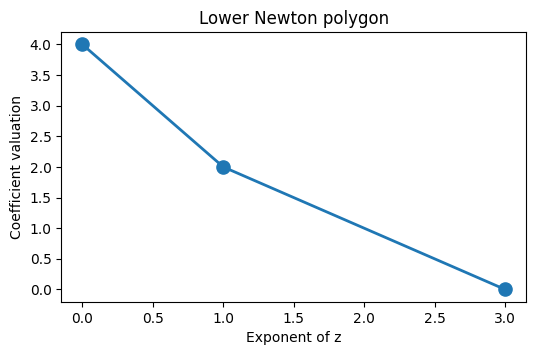

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from awa_lab.tropical import lower_newton_hull, root_valuation_prediction, trop_polynomial
vertices = [(0,4),(1,2),(3,0)]
hull=lower_newton_hull(vertices)
print('Lower hull:', hull)
print('Predicted valuations:',root_valuation_prediction(vertices))
eps=1e-4
roots=np.roots([1,0,eps**2,eps**4])
estimated=sorted(np.log(np.abs(roots))/np.log(eps), reverse=True)
print('Estimated log-slopes:',[round(float(u),4) for u in estimated])
fig,ax=plt.subplots(figsize=(6,3.5))
ax.scatter([a for a,b in vertices],[b for a,b in vertices],s=90)
ax.plot([a for a,b in hull],[b for a,b in hull],linewidth=2)
ax.set(xlabel='Exponent of z',ylabel='Coefficient valuation',title='Lower Newton polygon')
plt.show()
assert root_valuation_prediction(vertices)==[2,1,1]

## A tropical line, not a bent Euclidean one

For $1+x+y$, tropicalization yields the piecewise-linear function $\min(0,X,Y)$. The tropical hypersurface is **the locus where the minimum is attained at least twice**. Its three rays meet at the origin. Below we draw those rays and confirm the minimizer test at sample points.

(0, 2): min=0, terms attaining min=(0, 1), tropical=True
(3, 0): min=0, terms attaining min=(0, 2), tropical=True
(-1, -1): min=-1, terms attaining min=(1, 2), tropical=True
(2, 3): min=0, terms attaining min=(0,), tropical=False


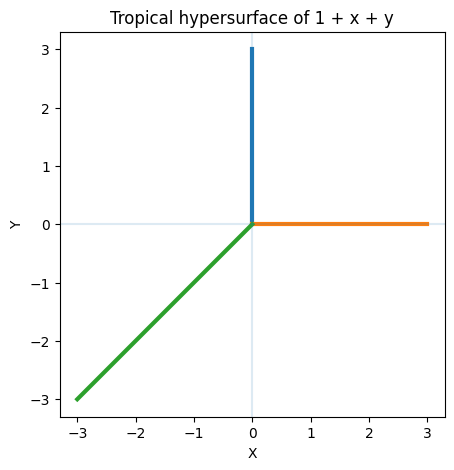

In [2]:
terms=[((0,0),0),((1,0),0),((0,1),0)]
for xy in [(0,2),(3,0),(-1,-1),(2,3)]:
    minimum, winners=trop_polynomial(terms,xy)
    print(f'{xy}: min={minimum}, terms attaining min={winners}, tropical={len(winners)>=2}')
r=np.linspace(0,3,150); n=np.linspace(-3,0,150)
fig,ax=plt.subplots(figsize=(5,5))
ax.plot(np.zeros_like(r),r,linewidth=3)
ax.plot(r,np.zeros_like(r),linewidth=3)
ax.plot(n,n,linewidth=3)
ax.set(xlim=(-3.3,3.3),ylim=(-3.3,3.3),xlabel='X',ylabel='Y',title='Tropical hypersurface of 1 + x + y')
ax.axhline(0,alpha=.15);ax.axvline(0,alpha=.15);ax.set_aspect('equal');plt.show()

## The trap: equations are not ideals

Tropicalizing a *list of generators* and intersecting their tropical hypersurfaces need not give the tropicalization of the ideal. In the Laurent polynomial ring over a trivially valued field of characteristic zero, consider

$$f=x+y+1,\qquad g=x+y+2.$$

Their tropical hypersurfaces coincide (all nonzero coefficients have valuation zero). But $g-f=1$, so the ideal $(f,g)$ is the **unit ideal**. It has empty variety and therefore empty tropicalization. The common tropical hypersurface is only a *tropical prevariety*. A tropical basis must capture the entire ideal.

In [3]:
x,y=sp.symbols('x y');f=x+y+1;g=x+y+2
GB=sp.groebner([f,g],x,y)
print('Groebner basis of (f,g):', [a.as_expr() for a in GB.polys])
assert GB.contains(sp.Integer(1))
print('Each generator has the same tropical line; the ideal has no points.')

Groebner basis of (f,g): [1]
Each generator has the same tropical line; the ideal has no points.


### Investigate

1. Determine the Newton polygon and root valuations predicted for $z^4+t z^2+t^6$. How many roots have each valuation?
2. For $f=1+x+y+xy$, sketch its tropical hypersurface. What changes if the coefficient of $xy$ has valuation $2$?
3. Explain the *initial ideal* criterion for tropical membership and why the unit-ideal example fails it for every weight.
4. Give an example of two different classical polynomials having the same tropical hypersurface; what is lost in tropicalization?

**Caution:** Real-valued numeric root sizes are illustrations only. Tropicalization is formulated via valuations and initial degenerations.